# kernel_bos -- 3-D Risk Geometry (fixed-points stop, no ATR)

Uses `Backtest_points.py` / `Analysis_points.py` -- stop sized as a FIXED NUMBER
OF POINTS instead of an ATR multiple, so the risk-geometry search is a genuine
3-D problem: **(stop points) x (risk% per trade) x (R:R) -> pass rate**.

`bars` load full 24h (`rth_only=False`) -- kernel/BOS `reset_daily` needs
pre-09:30 lookback bars to be valid at open. Knobs cell restricts to
`PERIOD_START` (2025-01-01) through end of file (currently 2026-08-17).

**`MAX_DAYS_TO_PASS`** (Knobs cell, currently 10) constrains every
selection in Sections 1-4 to cells/combos estimated to pass within that many
TRADING days for a SINGLE undiluted account -- not just highest pass_pct.
Section 6's own `MULTI_EVAL_MAX_DAYS` (25, declared locally in Section 6)
is a DELIBERATELY SEPARATE, more lenient per-attempt ceiling for diluted
concurrent accounts -- see the Knobs cell and Section 6 markdown for why.

**IS/OOS split** is an explicit calendar boundary (`IS_END`/`OOS_START` in
the Knobs cell, currently 2026-04-30 / 2026-05-01) -- Sections 1 and 4 SELECT
on `bars_is` only; `bars_oos` MEASURES the already-picked winner, never
re-optimizes. See 1b's markdown for the full history of why this split
moved from a 25%-fraction to explicit dates to a wider window (a 2-month
OOS was diagnosed as too noisy). Section 4/4b: the parameter-optimization
search (Stage A/B) has OVERFIT on every grid shape tried so far (large
IS->OOS collapses both times) -- treat `BEST_OVERRIDES` as a documented
cautionary result, not a recommendation, unless a future run finally holds
up out-of-sample.

**Sections:**
1/1b/2/2b/3 -- 3-D sweep (stop x risk% x R:R) at the active `OVERRIDES`, its
OOS check, and its top-cells table/chart.
4/4b -- parameter-optimization search (kernel_bos's own knobs) + its OOS check.
4c/4d -- multi-eval (see below) across Section 4's top 10 combos, on
`bars_oos` (4c) and on the FULL sample (4d, NOT a held-out test -- see its
own markdown).
5 -- manual verification (raw signals + trade log) for the active
`OVERRIDES`, most recent month of data.
6/6b -- multi-eval simulation: deterministic replay of `N_ACCOUNTS`
concurrent eval accounts (one trade/account/day, restart on breach) on
`bars_oos`, for Section 1's single `best` cell (6) and its top 10 (6b).
6c/6d -- same as 6/6b but on the FULL sample (NOT a held-out test -- see
their own markdown).


## Setup

In [1]:
import os, sys

# Machine-portable project-dir discovery: walk UP from wherever this kernel's
# cwd happens to be, and at each level search DOWN for the folder that
# actually contains Firms.py. No hardcoded path for a specific machine/user.
def find_project_dir(start=None, max_up=6):
    start = os.path.abspath(start or os.getcwd())
    skip = {"__pycache__", ".git", ".ipynb_checkpoints", "node_modules", "venv", ".venv"}
    cur = start
    for _ in range(max_up + 1):
        for root, dirs, files in os.walk(cur):
            dirs[:] = [d for d in dirs if d not in skip]
            if "Firms.py" in files:
                return root
        parent = os.path.dirname(cur)
        if parent == cur:
            break
        cur = parent
    return start   # last resort: leave cwd as-is rather than silently chdir'ing somewhere wrong


PROJECT_DIR = find_project_dir()
if "Firms.py" not in os.listdir(PROJECT_DIR):
    raise RuntimeError(
        f"Could not locate Firms.py starting from {os.getcwd()!r}. "
        f"Open this notebook from inside the repo before running the rest of the cells."
    )
os.chdir(PROJECT_DIR); sys.path.insert(0, PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: c:\Users\2115h\Desktop\Trading\Propfirm Convex Analysis\trading-code\Rules


In [2]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from Firms import FIRMS, get_firm
from Backtest_points import load_ohlc
from Analysis_points import risk_geometry_3d, plot_risk_geometry_3d, summary_table_3d, plot_top_cells, oos_check
from strategies.kernel_bos import get_strategy as get_kernel_bos
from strategies.time_window import TimeWindow

## Knobs

In [3]:
# ===================== THE ONLY CHOICES =====================
DATA_PATH = "data/NQ.ohlcv-1m.parquet"
FIRM      = get_firm("topstep")

# Full parquet goes back to 2021 -- restrict to the current regime.
# PERIOD_END=None -> through end of file (currently 2026-08-17).
PERIOD_START = "2025-01-01"
PERIOD_END   = None

# In-sample / out-of-sample split -- an EXPLICIT calendar boundary (not a
# fraction of days, so it doesn't silently slide as the data file grows).
# IS_END = last day in-sample; OOS_START = first day held out (inclusive).
# Sections 1 & 4 SELECT on bars_is only; bars_oos MEASURES (never
# re-optimizes) the already-picked winner -- see Analysis_points.oos_check().
# Widened 2026-08-19 from a July-Aug-only 2-month window (too noisy -- see
# 1b markdown for the diagnostic) to May-Aug.
IS_END     = "2026-04-30"
OOS_START  = "2026-05-01"

ENTRY_WINDOW_START = "09:30"       # entries constrained to this local wall-clock
ENTRY_WINDOW_END   = "11:00"       # window every day (start inclusive, end exclusive)
MAX_HOLD  = 120                    # bars (1-min) -- ~2h wall-clock ceiling, same as the ATR-based notebooks

# How many TRADING days a SINGLE undiluted account may take to hit the
# target before a cell/combo is disqualified from "best", regardless of
# pass rate (risk_geometry_3d()'s days_to_pass, from the Monte Carlo).
# DELIBERATELY SEPARATE from Section 6's own MULTI_EVAL_MAX_DAYS (25,
# declared locally there) -- this knob picks on UNDILUTED single-account
# pace; Section 6 spreads the same signals across concurrent accounts, so
# each slot naturally needs more calendar time and would fail this ceiling
# even for a cell that's genuinely fine once diluted. Tightened 2026-08-19
# from 25 -> 10 per explicit direction, precisely to force selection toward
# cells fast enough undiluted to still land within Section 6's looser
# ceiling once diluted across N_ACCOUNTS slots.
MAX_DAYS_TO_PASS = 10

# The literal numbers typed into the live TradingView "Kernel + BOS" indicator
# settings panel -- indicator params are OUT OF SCOPE for this notebook (see
# intro); edit these only to match a live panel change, not to sweep/tune.
OVERRIDES = dict(
    h=9, r=8, x_0=5,                  # Kernel (NW-RQK)
    bos_lookback=6,                    # BOS / structure
    slope_len=1, slope_min=0.30,       # Entry filters
    atr_len=14,                        # NOTE: kernel_bos's OWN slope filter still uses ATR
                                        # internally (strategies/kernel_bos.py) -- that's the
                                        # indicator's conviction filter, unrelated to the STOP
                                        # sizing this notebook pivots away from (Backtest.py's
                                        # k_stop_atr, now replaced by stop_points below).
    reset_daily=True,
    allow_long=True, allow_short=True,
)

# --- The 3-D sweep grids ---
STOP_GRID =  [25, 30, 35, 40, 45, 50, 55, 60]                                   # points

# Risk per trade -- ROUND FRACTIONS OF THE PROFIT TARGET (risk = target/N
# for whole N), not a flat %-of-balance ramp -- every grid point reads
# directly as "N winning trades (at 1R) would clear the target", e.g. N=5
# -> $600 -> "5 wins to pass". Descending N == ascending risk. Computed off
# FIRM.profit_target/start_balance so it stays correct if FIRM changes.
N_WINS_TO_PASS_GRID = [20, 15, 12, 10, 8, 6, 5, 4, 3]
RISK_PCTS = [FIRM.profit_target / n / FIRM.start_balance * 100 for n in N_WINS_TO_PASS_GRID]

RR_GRID   = [0.75, 1.0, 1.25, 1.5, 1.75, 2.0, 2.25, 2.5, 2.75, 3.0]        # target/stop

# Monte Carlo knobs (per cell -- 3-D grid is len(STOP_GRID)*len(RISK_PCTS)*len(RR_GRID) cells)
N_PATHS    = 2000
MAX_TRADES = 300
MIN_TRADES = 25     # hard floor -- a stop width needs at least this many measured entries to trust
# ============================================================

strat = TimeWindow(get_kernel_bos(**OVERRIDES), start=ENTRY_WINDOW_START, end=ENTRY_WINDOW_END)

# rth_only=False -- kernel/BOS reset_daily needs pre-09:30 lookback bars to
# be valid at market open; TimeWindow still only counts entries 09:30-11:00.
bars = load_ohlc(DATA_PATH, rth_only=False, timeframe=None, tz="America/New_York")
bars_full_range = (bars.index.min(), bars.index.max())
bars = bars.loc[PERIOD_START:PERIOD_END]   # PERIOD_END=None -> through the end of the file
print(f"Full file: {bars_full_range[0]} .. {bars_full_range[1]}")
print(f"Restricted to {bars.index.min()} .. {bars.index.max()}: "
      f"{len(bars):,} bars, {bars.index.normalize().nunique()} calendar days")
print("Risk-per-trade grid (N wins-to-pass -> $ -> % of start balance):")
for n, rp in zip(N_WINS_TO_PASS_GRID, RISK_PCTS):
    print(f"  N={n:>2d}  ${FIRM.profit_target / n:>7,.2f}  ({rp:.3f}% of ${FIRM.start_balance:,.0f})")
n_combos = len(STOP_GRID) * len(RISK_PCTS) * len(RR_GRID)
print(f"3-D grid: {len(STOP_GRID)} stop widths x {len(RISK_PCTS)} risk%s x {len(RR_GRID)} R:Rs "
      f"= {n_combos} cells ({len(STOP_GRID)} Entries ledgers to build)")
print(f"MAX_DAYS_TO_PASS = {MAX_DAYS_TO_PASS} trading days (single-account pace -- Section 6 uses "
      f"its own, separate MULTI_EVAL_MAX_DAYS) -- 'best' cells everywhere in Sections 1-4 are "
      f"constrained to this, not just highest pass_pct")

# --- In-sample / out-of-sample split (explicit calendar boundary -- see Knobs comment above) ---
_day_labels = bars.index.normalize()
_unique_days = np.sort(_day_labels.unique())
_is_end_ts = pd.Timestamp(IS_END, tz=bars.index.tz)
_oos_start_ts = pd.Timestamp(OOS_START, tz=bars.index.tz)
IS_DAYS, OOS_DAYS = _unique_days[_unique_days <= _is_end_ts], _unique_days[_unique_days >= _oos_start_ts]
bars_is = bars[_day_labels.isin(IS_DAYS)]
bars_oos = bars[_day_labels.isin(OOS_DAYS)]
print(f"\nIn-sample:     {bars_is.index.min()} .. {bars_is.index.max()}  "
      f"({len(bars_is):,} bars, {len(IS_DAYS)} days) -- Sections 1 & 4 select on this ONLY")
print(f"Out-of-sample: {bars_oos.index.min()} .. {bars_oos.index.max()}  "
      f"({len(bars_oos):,} bars, {len(OOS_DAYS)} days) -- held out, used ONLY to verify the winner (1b, 4b)")

Full file: 2021-06-27 20:00:00-04:00 .. 2026-08-17 13:09:00-04:00
Restricted to 2025-01-01 18:00:00-05:00 .. 2026-08-17 13:09:00-04:00: 572,778 bars, 508 calendar days
Risk-per-trade grid (N wins-to-pass -> $ -> % of start balance):
  N=20  $ 150.00  (0.300% of $50,000)
  N=15  $ 200.00  (0.400% of $50,000)
  N=12  $ 250.00  (0.500% of $50,000)
  N=10  $ 300.00  (0.600% of $50,000)
  N= 8  $ 375.00  (0.750% of $50,000)
  N= 6  $ 500.00  (1.000% of $50,000)
  N= 5  $ 600.00  (1.200% of $50,000)
  N= 4  $ 750.00  (1.500% of $50,000)
  N= 3  $1,000.00  (2.000% of $50,000)
3-D grid: 8 stop widths x 9 risk%s x 10 R:Rs = 720 cells (8 Entries ledgers to build)
MAX_DAYS_TO_PASS = 10 trading days (single-account pace -- Section 6 uses its own, separate MULTI_EVAL_MAX_DAYS) -- 'best' cells everywhere in Sections 1-4 are constrained to this, not just highest pass_pct



In-sample:     2025-01-01 18:00:00-05:00 .. 2026-04-30 23:59:00-04:00  (467,829 bars, 415 days) -- Sections 1 & 4 select on this ONLY
Out-of-sample: 2026-05-01 00:00:00-04:00 .. 2026-08-17 13:09:00-04:00  (104,949 bars, 93 days) -- held out, used ONLY to verify the winner (1b, 4b)


## 1) Run the 3-D sweep
Builds one `Entries` ledger per stop width (a different stop changes which
trades hit stop vs. target), then runs the risk%/R:R Monte Carlo at every
cell. Takes ~1-2 min for the default grid.

In [4]:
g = risk_geometry_3d(FIRM, strat, bars_is, STOP_GRID, RISK_PCTS, RR_GRID,
                    max_hold=MAX_HOLD, n_paths=N_PATHS, max_trades=MAX_TRADES,
                    min_trades=MIN_TRADES, seed=0, max_days_to_pass=MAX_DAYS_TO_PASS)

print("Entries per stop width (in-sample):")
for sp, n in zip(STOP_GRID, g["trades_grid"]):
    print(f"  {sp:>3g}pt  {int(n):>6,} entries")

b = g["best"]
tgt_pts = b["stop_points"] * b["rr"]
ceiling_note = "" if b["met_days_ceiling"] else \
    f"  [!] NOTHING on this grid passes within {MAX_DAYS_TO_PASS} trading days -- showing the unconstrained best instead"
print(f"\nBEST for {FIRM.name} (IN-SAMPLE): {b['stop_points']:g}pt stop / {tgt_pts:g}pt target "
      f"({b['rr']:g}R) @ {b['risk_pct']:.2f}% risk -> {b['pass_pct']:.0f}% pass "
      f"in ~{b['days_to_pass']:.0f} trading days (~{b['speed']:.0f} trades @ {b['trades_per_day']:.2f}/day, "
      f"WR {b['wr']:.0%}, n={b['trades']:,} entries at this stop width){ceiling_note}")

Entries per stop width (in-sample):
   25pt     858 entries
   30pt     792 entries
   35pt     740 entries
   40pt     699 entries
   45pt     659 entries
   50pt     636 entries
   55pt     609 entries
   60pt     594 entries

BEST for Topstep (Combine) (IN-SAMPLE): 25pt stop / 25pt target (1R) @ 1.20% risk -> 45% pass in ~8 trading days (~18 trades @ 2.53/day, WR 52%, n=858 entries at this stop width)


## 1b) Out-of-sample check
Measures the EXACT cell picked above (`g["best"]`) on `bars_oos` -- data the
sweep never saw. No re-optimization here, just a direct read of whether the
in-sample number holds up. A large pass-rate drop is the real overfitting
signal; Monte Carlo path-averaging alone can't catch it (see `oos_check()`'s
docstring).

**2026-08-19 diagnostic -- why `OOS_START` moved from 2026-07-01 to
2026-05-01:** a July-August-only OOS (41 days, 95 entries at the winning
30pt stop) collapsed to 6.7% pass vs. 46.6% IS (-39.9pp). Before treating
that as "the edge broke," a per-month breakdown of measured mean-R (30pt
stop, checked across RR=1/1.5/2/2.5/3, not just the winning 2.5R cell) over
the full 2025-2026 history was run: July 2026 (mean_R -0.30 @ 2.5R) was
comparable to several OTHER months well inside `bars_is` that never showed
up as a problem because they were diluted by the other ~20 months around
them -- March 2025 (-0.39), August 2025 (-0.21), March 2026 (-0.28), April
2026 (-0.19) all had similarly bad stretches. August 2026 (the OOS window's
other month) was fine (+0.13). This is consistent with normal month-to-month
variance the strategy has always had, not a new regime break -- but a
2-month OOS sample is simply too small to distinguish "one bad month" from
"broken edge" on its own. Widening `OOS_START` to 2026-05-01 (May-August,
219 entries) recovers pass_pct to ~30% and mean_R to roughly breakeven --
still below the IS read, so some optimism bias likely remains (the winning
cell WAS picked via a 720-cell argmax search on `bars_is`, which the
`risk_geometry_3d()` docstring already flags as a multiple-comparisons risk
independent of this), but nowhere near the 2-month window's near-total
collapse. Do not shrink `OOS_START` back toward July without a good reason
-- the whole point of this fix was that a 2-month/~100-trade OOS window is
too noisy to trust on its own for a strategy this close to its breakeven win
rate (measured WR is often within a few points of `1/(1+RR)`).

In [5]:
oos = oos_check(FIRM, strat, bars_oos, stop_points=g["best"]["stop_points"],
                rr=g["best"]["rr"], risk_pct=g["best"]["risk_pct"],
                max_hold=MAX_HOLD, n_paths=N_PATHS, max_trades=MAX_TRADES, seed=0)

b = g["best"]
print(f"IN-SAMPLE  ({len(bars_is):,} bars / {len(IS_DAYS)} days): "
      f"{b['pass_pct']:.1f}% pass, ~{b['days_to_pass']:.0f}d to pass, WR {b['wr']:.0%} (n={b['trades']:,})")
if oos["warning"]:
    print(f"OUT-OF-SAMPLE ({len(bars_oos):,} bars / {len(OOS_DAYS)} days): [!] {oos['warning']}")
else:
    print(f"OUT-OF-SAMPLE ({len(bars_oos):,} bars / {len(OOS_DAYS)} days): "
          f"{oos['pass_pct']:.1f}% pass, ~{oos['days_to_pass']:.0f}d to pass, WR {oos['wr']:.0%} (n={oos['trades']:,})")
    drop = b["pass_pct"] - oos["pass_pct"]
    verdict = "looks robust" if abs(drop) < 15 else "[!] LARGE DROP -- treat the in-sample number with suspicion"
    print(f"\nIS -> OOS pass-rate change: {-drop:+.1f}pp  ({verdict})")

IN-SAMPLE  (467,829 bars / 415 days): 45.1% pass, ~8d to pass, WR 52% (n=858)
OUT-OF-SAMPLE (104,949 bars / 93 days): 35.7% pass, ~8d to pass, WR 51% (n=227)

IS -> OOS pass-rate change: -9.5pp  (looks robust)


## 2) Top cells (text)

In [6]:
df = summary_table_3d(g, top_n=15, max_days_to_pass=MAX_DAYS_TO_PASS)
print(df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

 stop_pts  target_pts    rr  risk_pct  pass_pct  speed  days_to_pass  trades_per_day    wr  trades
   25.000      25.000 1.000     1.200    45.150 18.167         8.007           2.531 0.519     858
   25.000      25.000 1.000     1.500    44.250 12.749         5.779           2.531 0.519     858
   25.000      75.000 3.000     0.600    43.550 21.561         9.735           2.531 0.259     858
   30.000      75.000 2.500     1.200    43.200  9.824         5.130           2.336 0.294     792
   30.000      60.000 2.000     1.200    42.250 12.228         6.186           2.336 0.343     792
   25.000      75.000 3.000     0.750    42.000 16.126         7.442           2.531 0.259     858
   25.000      37.500 1.500     1.000    41.950 18.529         8.379           2.531 0.418     858
   25.000      50.000 2.000     0.750    41.750 20.925         9.329           2.531 0.344     858
   25.000      43.750 1.750     1.200    41.500 15.041         6.907           2.531 0.382     858
   25.000 

## 2b) Top cells (chart)
Same cells as the text table above, as a ranked bar chart -- bar length is
pass rate (what it's ranked by), bar color is days-to-pass (green=faster,
red=slower), so the pass-rate/speed trade-off is visible in one glance.

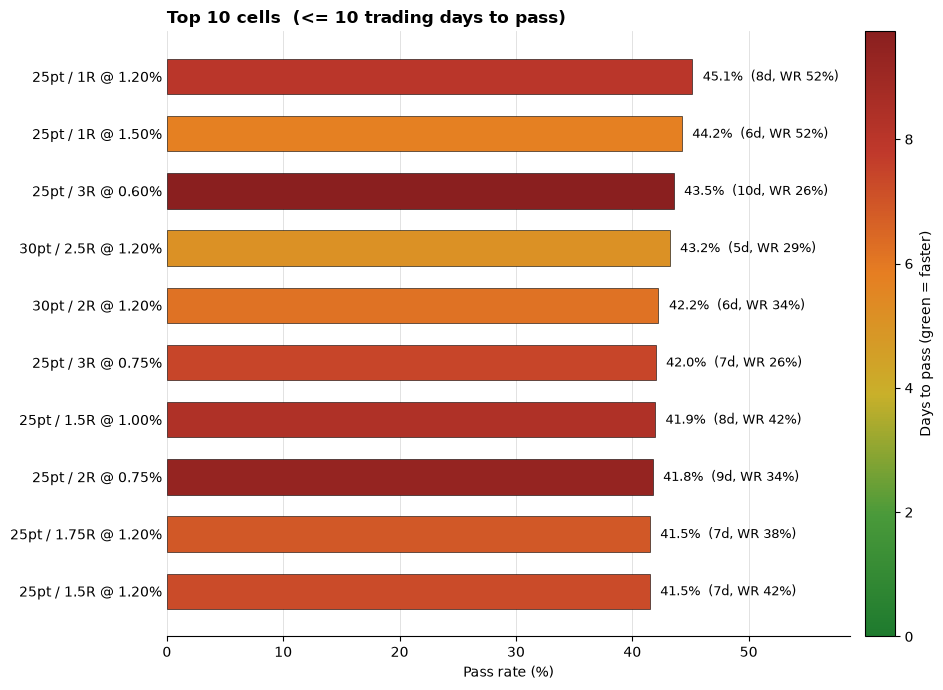

In [7]:
fig = plot_top_cells(g, top_n=10, max_days_to_pass=MAX_DAYS_TO_PASS)
plt.show()

## 3) 3-D risk-geometry chart

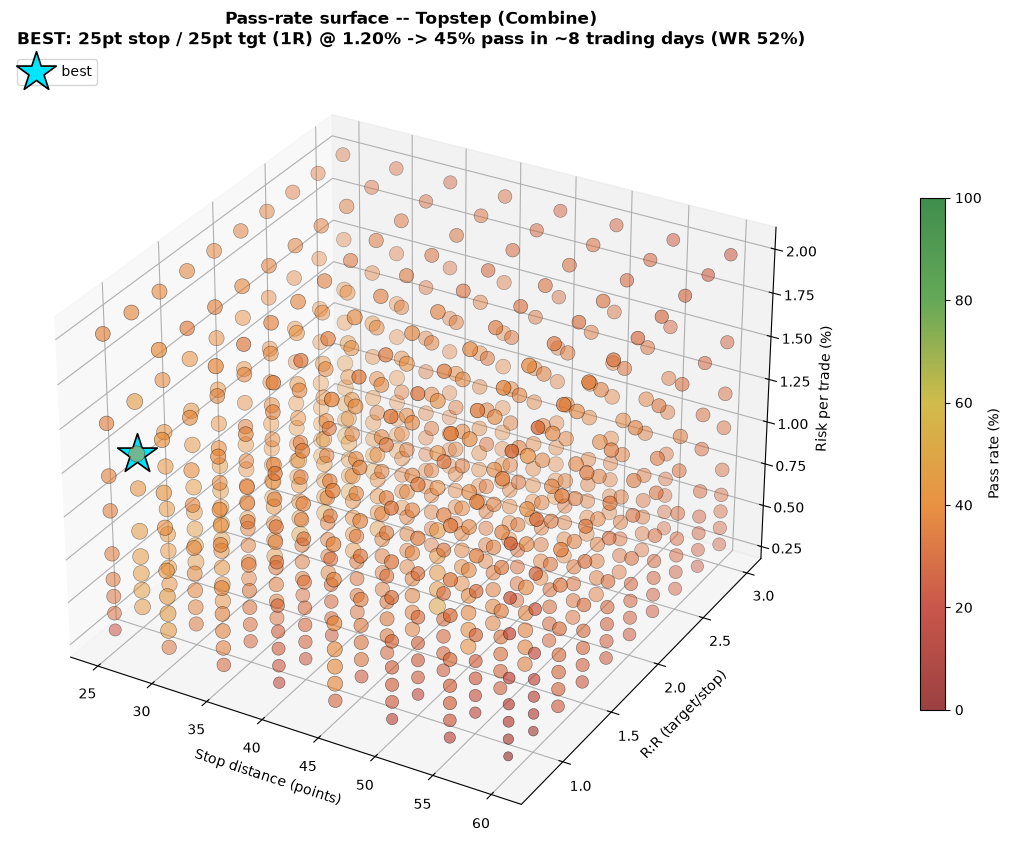

In [8]:
fig = plot_risk_geometry_3d(FIRM, g)
plt.show()

## 4) Parameter optimization -- kernel_bos indicator params
Sweeps `kernel_bos`'s own knobs (`h`, `r`, `x_0`, `bos_lookback`, `slope_len`,
`slope_min`) -- same widened grids as the ATR-based notebook's Section 6
(`x_0`/`bos_lookback`/`slope_len` extended to also cover the wall-clock-
equivalent of the old 3-min ranges, since 1-min bars are 3x finer).

Two stages, so the expensive part only runs on combos worth it:

1. **Stage A (fast, no Monte Carlo)** -- grid over the knobs above, EACH AT
   ONE representative stop width (`STAGE_A_STOP_POINTS`, the midpoint of
   `STOP_GRID`). Ranked by `edge_per_day = (mean measured edge @ 1/1.5/2/3R)
   x (measured trades/day)` -- NOT raw edge alone. A combo with slightly
   lower per-trade edge but noticeably higher frequency compounds toward the
   profit target faster in real calendar time, which raw edge ignores
   completely. This is only a screen to shortlist candidates -- it does NOT
   claim that stop width is optimal for any of them, and it can't compute a
   true days-to-pass (that needs the Monte Carlo below).
2. **Stage B (full 3-D Monte Carlo)** -- for each of the `TOP_N` Stage-A
   survivors, runs the COMPLETE `risk_geometry_3d()` sweep (stop x risk% x
   R:R, same as Section 1, same `MAX_DAYS_TO_PASS` constraint) and takes ITS
   OWN best cell. This is the fix for the ATR notebook's confound: there,
   the param sweep held stop width fixed at a guess (`k_stop_atr=3`) the
   whole time, so `BEST_OVERRIDES` was never actually optimal -- it was just
   the best params GIVEN a stop width nobody checked. Here every survivor
   gets its stop/risk%/R:R re-optimized from scratch, under the same
   real-world speed constraint, before being compared.

The winning combo's own full 3-D risk-geometry matrix is plotted at the end.


In [9]:
# ===================== PARAMETER SWEEP KNOBS =====================
# Narrowed 2026-08-19 per explicit direction (was H_GRID/X0_GRID=[5,6,8,10],
# SLOPE_LEN_GRID=[1,3,5], SLOPE_MIN_GRID=[0.1,0.3,0.5]) -- extends H/X0 up to
# 12 and narrows SLOPE_LEN_GRID to just 1 (drop the 3/5 lookbacks) while
# widening SLOPE_MIN_GRID's resolution (added 0.4).
H_GRID              = [5, 6, 8, 10, 12]         # kernel bandwidth
R_GRID              = [8]                       # kernel relative weighting
X0_GRID             = [5, 6, 8, 10, 12]         # kernel window length, bars
BOS_LOOKBACK_GRID   = [6]                       # BOS structure lookback, bars
SLOPE_LEN_GRID      = [1]                       # slope-filter lookback, bars
SLOPE_MIN_GRID      = [0.1, 0.3, 0.4, 0.5]      # ATR-normalized slope threshold (unitless ratio --
                                                  # kernel_bos's OWN conviction filter, unrelated to
                                                  # the stop-sizing ATR this notebook removed)

STAGE_A_STOP_POINTS = STOP_GRID[len(STOP_GRID)//2]   # midpoint of STOP_GRID -- Stage A screening only
MIN_TRADES          = 150    # hard floor -- absolute entry count over the full backtest
MIN_TRADES_PER_DAY  = 0.20   # hard floor -- kernel_bos + TimeWindow trades far less than an unconstrained strategy
EDGE_RR_CHECK       = [1.0, 1.5, 2.0, 3.0]   # Stage-A score = mean measured edge across these RRs
TOP_N               = 10     # how many Stage-A survivors get the full Stage-B 3-D sweep -- raised
                              # from 8 to 10 2026-08-19 so Stage B actually produces a top-10 ranking
# ===================================================================

n_combos = (len(H_GRID)*len(R_GRID)*len(X0_GRID)*len(BOS_LOOKBACK_GRID)
           *len(SLOPE_LEN_GRID)*len(SLOPE_MIN_GRID))
print(f"Stage A grid: {n_combos} combos @ {STAGE_A_STOP_POINTS}pt stop (fast -- no Monte Carlo)")
print(f"Stage B: full risk_geometry_3d() on the top {TOP_N} of those "
      f"({len(STOP_GRID)*len(RISK_PCTS)*len(RR_GRID)} cells each -- slower)\n")
print("Ranges swept this run:")
for label, grid in [("h", H_GRID), ("r", R_GRID), ("x_0", X0_GRID),
                    ("bos_lookback", BOS_LOOKBACK_GRID),
                    ("slope_len", SLOPE_LEN_GRID), ("slope_min", SLOPE_MIN_GRID)]:
    print(f"  {label:14s} {grid}   (min={min(grid)}, max={max(grid)}, n={len(grid)})")

Stage A grid: 100 combos @ 45pt stop (fast -- no Monte Carlo)
Stage B: full risk_geometry_3d() on the top 10 of those (720 cells each -- slower)

Ranges swept this run:
  h              [5, 6, 8, 10, 12]   (min=5, max=12, n=5)
  r              [8]   (min=8, max=8, n=1)
  x_0            [5, 6, 8, 10, 12]   (min=5, max=12, n=5)
  bos_lookback   [6]   (min=6, max=6, n=1)
  slope_len      [1]   (min=1, max=1, n=1)
  slope_min      [0.1, 0.3, 0.4, 0.5]   (min=0.1, max=0.5, n=4)


In [10]:
# === STAGE A: fast prefilter -- edge_per_day at one stop width, no Monte Carlo (IN-SAMPLE) ===
import itertools
import pandas as pd
import numpy as np
from Backtest_points import backtest_entries, ledger_for_rr, measured_winrate

combos = list(itertools.product(H_GRID, R_GRID, X0_GRID, BOS_LOOKBACK_GRID,
                                SLOPE_LEN_GRID, SLOPE_MIN_GRID))
rows_a = []
for h, r, x0, bl, sl, sm in combos:
    s = TimeWindow(get_kernel_bos(h=h, r=r, x_0=x0, bos_lookback=bl,
                                  slope_len=sl, slope_min=sm),
                   start=ENTRY_WINDOW_START, end=ENTRY_WINDOW_END)
    E_a = backtest_entries(s, bars_is, stop_points=STAGE_A_STOP_POINTS, max_hold=MAX_HOLD)
    n_trades = len(E_a.day_ids)
    if n_trades < MIN_TRADES or n_trades / max(E_a.n_days, 1) < MIN_TRADES_PER_DAY:
        continue   # HARD floors: enough trades AND enough trades/day
    edges = {rr: ledger_for_rr(E_a, rr)[0].mean() for rr in EDGE_RR_CHECK}
    trades_per_day = n_trades / max(E_a.n_days, 1)
    score = float(np.mean(list(edges.values())))
    rows_a.append(dict(h=h, r=r, x_0=x0, bos_lookback=bl, slope_len=sl, slope_min=sm,
                       trades=n_trades, trades_per_day=trades_per_day,
                       wr_1R=measured_winrate(E_a, 1.0),
                       **{f"edge_{rr}R": edges[rr] for rr in EDGE_RR_CHECK},
                       score=score, edge_per_day=score * trades_per_day))

# Ranked by edge_per_day (R generated per calendar trading day), NOT raw
# score -- a combo with a smaller per-trade edge but noticeably higher
# frequency reaches a profit target faster in real time, which "score" alone
# can't tell you (see Section 4 intro).
sweep_df = pd.DataFrame(rows_a).sort_values("edge_per_day", ascending=False)
print(f"{len(sweep_df)} / {len(combos)} combos cleared the trade-count floors "
      f"(stop={STAGE_A_STOP_POINTS}pt, in-sample only: {len(bars_is):,} bars / {len(IS_DAYS)} days)\n")
print(f"--- TOP {TOP_N} by Stage-A edge_per_day (score x trades/day; "
      f"score = mean measured edge @ {EDGE_RR_CHECK}) ---")
print(sweep_df.head(TOP_N).to_string(index=False, float_format=lambda x: f"{x:.3f}"))

94 / 100 combos cleared the trade-count floors (stop=45pt, in-sample only: 467,829 bars / 415 days)

--- TOP 10 by Stage-A edge_per_day (score x trades/day; score = mean measured edge @ [1.0, 1.5, 2.0, 3.0]) ---
 h  r  x_0  bos_lookback  slope_len  slope_min  trades  trades_per_day  wr_1R  edge_1.0R  edge_1.5R  edge_2.0R  edge_3.0R  score  edge_per_day
12  8   12             6          1      0.400     192           1.178  0.557      0.123      0.210      0.218      0.268  0.205         0.241
 8  8   12             6          1      0.400     248           1.204  0.524      0.061      0.183      0.222      0.290  0.189         0.227
10  8   12             6          1      0.400     213           1.190  0.540      0.088      0.173      0.217      0.271  0.187         0.223
12  8    8             6          1      0.500     193           1.163  0.565      0.132      0.219      0.188      0.225  0.191         0.222
10  8    8             6          1      0.500     199           1.185  0

In [11]:
# === STAGE B: full 3-D risk-geometry sweep (stop x risk% x R:R) on the Stage-A survivors (IN-SAMPLE) ===
rows_b = []
geometries_b = {}
for _, row in sweep_df.head(TOP_N).iterrows():
    overrides_b = dict(h=float(row["h"]), r=float(row["r"]), x_0=int(row["x_0"]),
                       bos_lookback=int(row["bos_lookback"]), slope_len=int(row["slope_len"]),
                       slope_min=float(row["slope_min"]))
    s = TimeWindow(get_kernel_bos(**overrides_b), start=ENTRY_WINDOW_START, end=ENTRY_WINDOW_END)
    g_b = risk_geometry_3d(FIRM, s, bars_is, STOP_GRID, RISK_PCTS, RR_GRID,
                           max_hold=MAX_HOLD, n_paths=N_PATHS, max_trades=MAX_TRADES,
                           min_trades=MIN_TRADES, seed=0, max_days_to_pass=MAX_DAYS_TO_PASS)
    key = tuple(sorted(overrides_b.items()))
    geometries_b[key] = g_b
    b = g_b["best"]
    rows_b.append({**overrides_b, "stop_points": b["stop_points"], "rr": b["rr"],
                   "target_pts": b["stop_points"]*b["rr"], "risk_pct": b["risk_pct"],
                   "pass_pct": b["pass_pct"], "speed": b["speed"],
                   "days_to_pass": b["days_to_pass"], "met_ceiling": b["met_days_ceiling"],
                   "wr": b["wr"]})

# Sorted by pass_pct among cells that already satisfy MAX_DAYS_TO_PASS (each
# survivor's own g_b["best"] was picked under that same constraint) -- this
# IS the "good enough pass rate in a short amount of time" sweet spot, not
# just the single highest pass_pct on the whole search space.
geometry_df = pd.DataFrame(rows_b).sort_values(["met_ceiling", "pass_pct", "speed"],
                                               ascending=[False, False, True])
print(f"--- Stage B: full 3-D risk-geometry search, {FIRM.name} (IN-SAMPLE, "
      f"MAX_DAYS_TO_PASS={MAX_DAYS_TO_PASS}-constrained where possible) ---")
print(geometry_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
if not geometry_df["met_ceiling"].all():
    print(f"\n[!] {int((~geometry_df['met_ceiling']).sum())}/{len(geometry_df)} survivors have "
          f"NO cell that passes within {MAX_DAYS_TO_PASS} trading days -- their row shows the "
          f"unconstrained best instead (flagged met_ceiling=False), and they're ranked below "
          f"anything that DID meet the ceiling.")

BEST_OVERRIDES = geometry_df.iloc[0][["h", "r", "x_0", "bos_lookback", "slope_len", "slope_min"]].to_dict()
BEST_OVERRIDES = {k: (int(v) if k in ("x_0", "bos_lookback", "slope_len") else float(v))
                  for k, v in BEST_OVERRIDES.items()}
BEST_G = geometries_b[tuple(sorted(BEST_OVERRIDES.items()))]
print("\nBEST combo found (IN-SAMPLE) -- paste into OVERRIDES in the Knobs cell to make it the active strategy:")
print(BEST_OVERRIDES)
print("Check 4b below before trusting this -- it's an in-sample number from a search over "
      f"{TOP_N} x {len(STOP_GRID)*len(RISK_PCTS)*len(RR_GRID)} cells.")

--- Stage B: full 3-D risk-geometry search, Topstep (Combine) (IN-SAMPLE, MAX_DAYS_TO_PASS=10-constrained where possible) ---
     h     r  x_0  bos_lookback  slope_len  slope_min  stop_points    rr  target_pts  risk_pct  pass_pct  speed  days_to_pass  met_ceiling    wr
10.000 8.000    8             6          1      0.500       45.000 1.750      78.750     1.200    60.100 10.324         8.890         True 0.427
12.000 8.000    8             6          1      0.500       45.000 1.500      67.500     1.200    59.000 11.168         9.773         True 0.472
 8.000 8.000    8             6          1      0.500       40.000 2.000      80.000     1.200    58.350  8.793         7.481         True 0.402
12.000 8.000   12             6          1      0.400       45.000 1.500      67.500     1.200    57.800 10.997         9.540         True 0.469
12.000 8.000   10             6          1      0.400       45.000 1.750      78.750     1.200    56.750 11.111         9.255         True 0.411
10.0

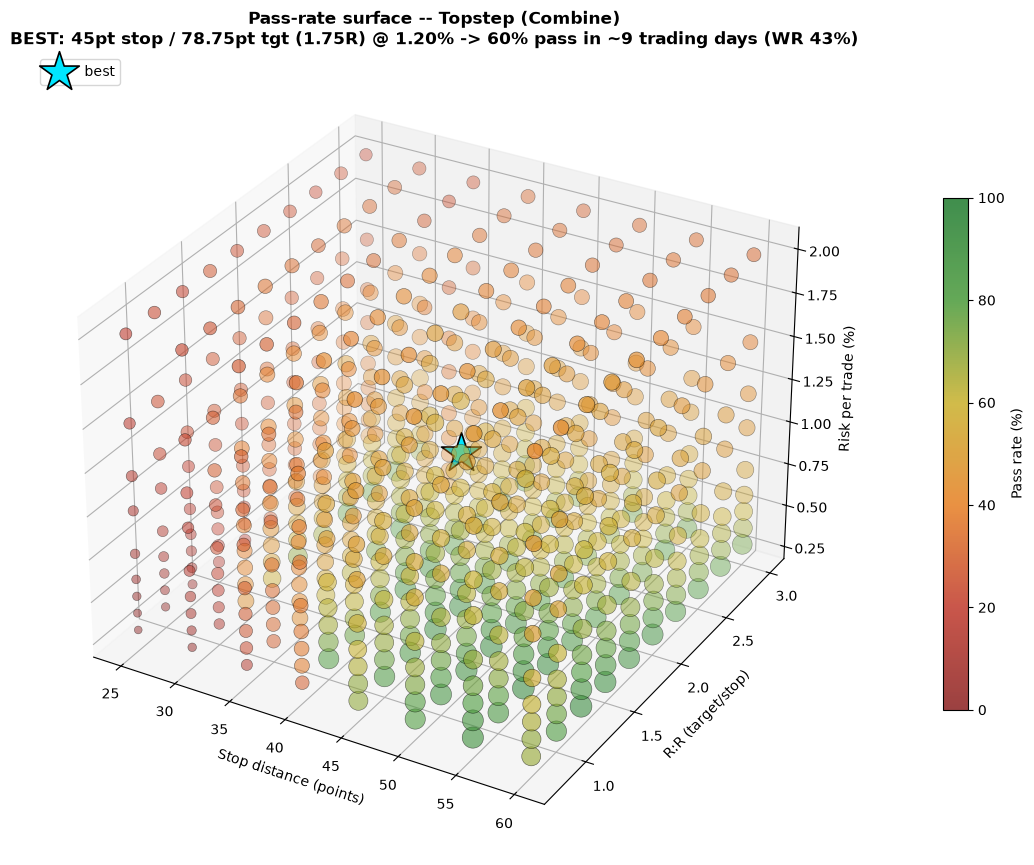

BEST swept combo for Topstep (Combine): {'h': 10.0, 'r': 8.0, 'x_0': 8, 'bos_lookback': 6, 'slope_len': 1, 'slope_min': 0.5}
  -> 45pt stop / 78.75pt target (1.75R) @ 1.20% risk = 60% pass in ~9 trading days (~10 trades @ 1.18/day, WR 43%)


In [12]:
# === Full 3-D risk-geometry matrix for the winning param combo ===
fig = plot_risk_geometry_3d(FIRM, BEST_G)
plt.show()
b = BEST_G["best"]
ceiling_note = "" if b["met_days_ceiling"] else \
    f"  [!] NO cell for this combo passes within {MAX_DAYS_TO_PASS} trading days"
print(f"BEST swept combo for {FIRM.name}: {BEST_OVERRIDES}")
print(f"  -> {b['stop_points']:g}pt stop / {b['stop_points']*b['rr']:g}pt target ({b['rr']:g}R) "
      f"@ {b['risk_pct']:.2f}% risk = {b['pass_pct']:.0f}% pass in ~{b['days_to_pass']:.0f} trading days "
      f"(~{b['speed']:.0f} trades @ {b['trades_per_day']:.2f}/day, WR {b['wr']:.0%}){ceiling_note}")

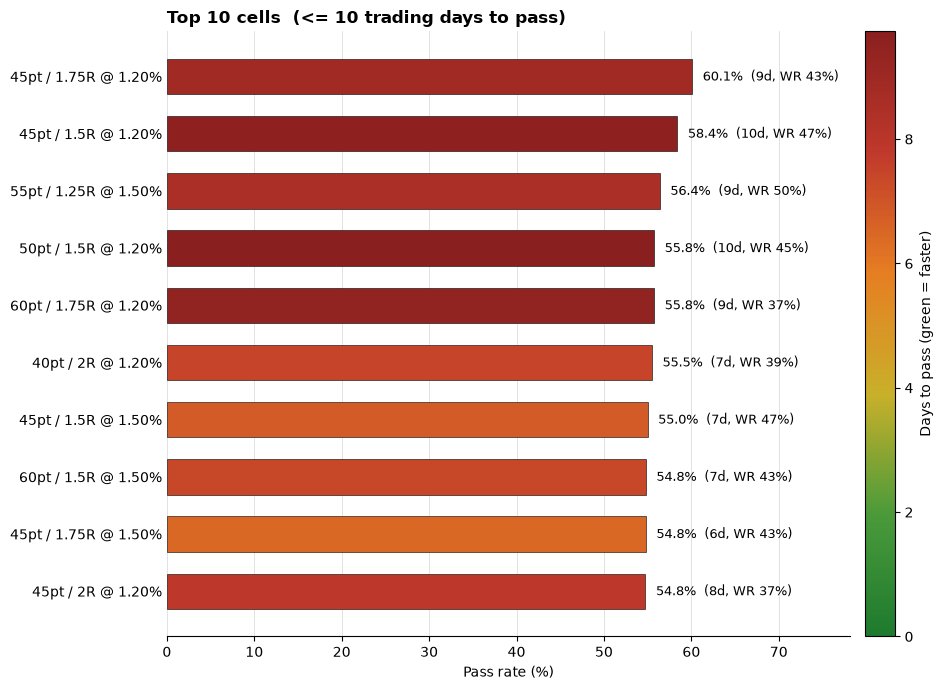

In [13]:
# === Top cells for the winning param combo, same chart as 2b ===
fig = plot_top_cells(BEST_G, top_n=10, max_days_to_pass=MAX_DAYS_TO_PASS)
plt.show()

## 4b) Out-of-sample check for BEST_OVERRIDES
The real test of everything above. Stage A/B searched a large space (params
x stop x risk% x R:R) purely on `bars_is` -- this measures the EXACT winning
combo (`BEST_OVERRIDES` + `BEST_G["best"]`'s stop/risk%/R:R) on `bars_oos`,
which never influenced the search. No re-optimization. If the pass rate
survives roughly intact, the edge is probably real; if it collapses, the
search found noise, not signal -- go back to Section 4 with tighter floors
or fewer params, not a wider grid.

In [14]:
strat_best = TimeWindow(get_kernel_bos(**BEST_OVERRIDES), start=ENTRY_WINDOW_START, end=ENTRY_WINDOW_END)
oos_best = oos_check(FIRM, strat_best, bars_oos, stop_points=BEST_G["best"]["stop_points"],
                     rr=BEST_G["best"]["rr"], risk_pct=BEST_G["best"]["risk_pct"],
                     max_hold=MAX_HOLD, n_paths=N_PATHS, max_trades=MAX_TRADES, seed=0)

b = BEST_G["best"]
print(f"IN-SAMPLE  ({len(bars_is):,} bars / {len(IS_DAYS)} days): "
      f"{b['pass_pct']:.1f}% pass, ~{b['days_to_pass']:.0f}d to pass, WR {b['wr']:.0%} (n={b['trades']:,})")
if oos_best["warning"]:
    print(f"OUT-OF-SAMPLE ({len(bars_oos):,} bars / {len(OOS_DAYS)} days): [!] {oos_best['warning']}")
else:
    print(f"OUT-OF-SAMPLE ({len(bars_oos):,} bars / {len(OOS_DAYS)} days): "
          f"{oos_best['pass_pct']:.1f}% pass, ~{oos_best['days_to_pass']:.0f}d to pass, "
          f"WR {oos_best['wr']:.0%} (n={oos_best['trades']:,})")
    drop = b["pass_pct"] - oos_best["pass_pct"]
    verdict = "looks robust" if abs(drop) < 15 else \
        "[!] LARGE DROP -- BEST_OVERRIDES likely doesn't generalize; the Stage A/B search found noise"
    print(f"\nIS -> OOS pass-rate change: {-drop:+.1f}pp  ({verdict})")

IN-SAMPLE  (467,829 bars / 415 days): 60.1% pass, ~9d to pass, WR 43% (n=199)
OUT-OF-SAMPLE (104,949 bars / 93 days): 30.5% pass, ~9d to pass, WR 36% (n=42)

IS -> OOS pass-rate change: -29.6pp  ([!] LARGE DROP -- BEST_OVERRIDES likely doesn't generalize; the Stage A/B search found noise)


## 4c) Multi-eval across the top 10 parameter-optimization results
Section 6b sweeps stop/R:R/risk% at FIXED indicator params (the active
`OVERRIDES`). This instead takes the top 10 rows of `geometry_df` -- 10
DIFFERENT `kernel_bos` indicator-param combos, each already carrying its own
Stage-B-optimized stop/R:R/risk% (`geometries_b[key]["best"]`) -- and runs
each one through the SAME `N_ACCOUNTS`-slot, restart-on-breach multi-eval
replay on the full `bars_oos`. A different param combo changes the actual
ENTRY signals (not just the stop/target), so each row needs its own
strategy AND its own fresh `Entries` ledger -- no caching across rows here
(unlike 6b, where multiple ranked cells could share one stop-width ledger).

This is the parameter-search analogue of 6b's question: does the combo
Stage B ranks #1 by single-account IS pass_pct also hold up best once its
signals get diluted across concurrent, restart-on-breach accounts over real
OOS history -- or, like 6b found for stop/R:R/risk% alone, does the ranking
shuffle once multi-eval is the yardstick?

In [15]:
# Self-contained (doesn't assume Section 6 already ran) -- same constants/imports as Section 6.
from Backtest_points import backtest_entries as backtest_entries_verify
from MultiEval import multi_account_replay

N_ACCOUNTS = 3            # same as Section 6 -- concurrent evals to model
MULTI_EVAL_MAX_DAYS = 25  # same as Section 6 -- this notebook's multi-eval patience ceiling

top10_params = geometry_df.head(10)

rows_multi_params = []
results_top10_params = []   # (rank, row, MultiEvalResult) -- kept for the chart cell below

for rank, row in enumerate(top10_params.itertuples(index=False), start=1):
    overrides_i = dict(h=row.h, r=row.r, x_0=int(row.x_0), bos_lookback=int(row.bos_lookback),
                       slope_len=int(row.slope_len), slope_min=row.slope_min)
    s_i = TimeWindow(get_kernel_bos(**overrides_i), start=ENTRY_WINDOW_START, end=ENTRY_WINDOW_END)
    E_i = backtest_entries_verify(s_i, bars_oos, stop_points=row.stop_points,
                                  max_hold=MAX_HOLD, detail=True)

    res_i = multi_account_replay(E_i, FIRM, risk_pct=row.risk_pct, rr=row.rr,
                                 n_accounts=N_ACCOUNTS, max_days=MULTI_EVAL_MAX_DAYS,
                                 restart_on_fail=True)
    results_top10_params.append((rank, row, res_i))
    rows_multi_params.append(dict(
        rank=rank, h=row.h, x_0=int(row.x_0), slope_min=row.slope_min,
        stop_pts=row.stop_points, rr=row.rr, risk_pct=row.risk_pct,
        is_pass_pct=row.pass_pct, is_days_to_pass=row.days_to_pass,
        attempts=res_i.n_attempts, passed=res_i.n_passed, blown=res_i.n_blown,
        timeout=res_i.n_timeout, multi_pass_rate=res_i.pass_rate * 100,
        entries_used=res_i.entries_used,
    ))

multi_top10_params_df = pd.DataFrame(rows_multi_params)
print(f"Multi-eval ({N_ACCOUNTS} slots, restart-on-breach, max_days={MULTI_EVAL_MAX_DAYS}) "
      f"across the top {len(top10_params)} parameter-optimization results, each combo's OWN "
      f"Stage-B-winning stop/R:R/risk%, replayed on the full bars_oos "
      f"({len(bars_oos.index.normalize().unique())} days):\n")
print(multi_top10_params_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\n'multi_pass_rate' = passed / (passed + blown), same convention as Sections 6/6b.")

Multi-eval (3 slots, restart-on-breach, max_days=25) across the top 10 parameter-optimization results, each combo's OWN Stage-B-winning stop/R:R/risk%, replayed on the full bars_oos (93 days):

 rank      h  x_0  slope_min  stop_pts    rr  risk_pct  is_pass_pct  is_days_to_pass  attempts  passed  blown  timeout  multi_pass_rate  entries_used
    1 10.000    8      0.500    45.000 1.750     1.200       60.100            8.890         6       1      3        0           25.000            42
    2 12.000    8      0.500    45.000 1.500     1.200       59.000            9.773         6       0      3        0            0.000            42
    3  8.000    8      0.500    40.000 2.000     1.200       58.350            7.481         6       2      3        0           40.000            43
    4 12.000   12      0.400    45.000 1.500     1.200       57.800            9.540         5       1      2        0           33.333            47
    5 12.000   10      0.400    45.000 1.750     1.200  

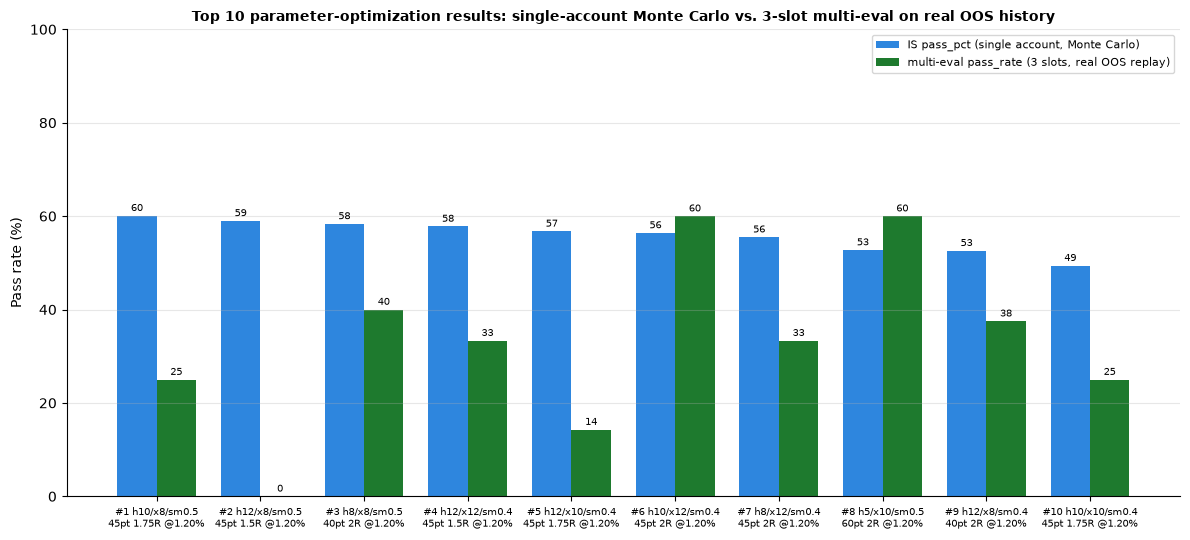

In [16]:
# === Grouped bar chart: IS single-account pass_pct vs. multi-eval pass_rate, per param combo ===
fig, ax = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(multi_top10_params_df))
w = 0.38
labels = [f"#{r.rank} h{r.h:g}/x{r.x_0}/sm{r.slope_min:g}\n{r.stop_pts:g}pt {r.rr:g}R @{r.risk_pct:.2f}%"
         for r in multi_top10_params_df.itertuples()]

b1 = ax.bar(x - w/2, multi_top10_params_df["is_pass_pct"], width=w, color="#2e86de",
           label="IS pass_pct (single account, Monte Carlo)")
b2 = ax.bar(x + w/2, multi_top10_params_df["multi_pass_rate"], width=w, color="#1e7a2e",
           label=f"multi-eval pass_rate ({N_ACCOUNTS} slots, real OOS replay)")

for bar_group in (b1, b2):
    for bar in bar_group:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.0f}", ha="center", fontsize=7)

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("Pass rate (%)")
ax.set_ylim(0, 100)
ax.set_title(f"Top {len(multi_top10_params_df)} parameter-optimization results: single-account "
            f"Monte Carlo vs. {N_ACCOUNTS}-slot multi-eval on real OOS history",
            fontweight="bold", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.3, axis="y")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

## 4d) FULL-SAMPLE multi-eval across the top 10 parameter-optimization results
**Not a held-out test -- read this alongside 4c, not instead of it.** Same
top-10 param combos as 4c, same `N_ACCOUNTS`/`MULTI_EVAL_MAX_DAYS`, but
replayed on `bars` (`PERIOD_START` .. end of file, `bars_is` + `bars_oos`
combined, ~508 days) instead of just `bars_oos` (93 days). 4c's per-combo
attempt counts were thin (5-9 total attempts each) -- this gives each combo
5-6x more calendar days to accumulate attempts, directly addressing that
noise. The cost: every one of these combos was SELECTED because it scored
well on `bars_is` (Section 4's Stage A/B search never saw `bars_oos` when
picking them) -- replaying on `bars_is` again as part of "full sample" is
partly re-measuring performance on the same data that picked the winner,
which biases these numbers OPTIMISTIC relative to a genuine out-of-sample
read, for reasons unrelated to real edge. 4c remains the actual overfitting
check; this is a bigger-sample operational reference, not a replacement for
it -- treat any gap between the two as expected, not a contradiction.

In [17]:
# Self-contained -- same pattern as 4c, bars_oos -> bars (full sample).
rows_multi_params_full = []
results_top10_params_full = []

for rank, row in enumerate(top10_params.itertuples(index=False), start=1):
    overrides_i = dict(h=row.h, r=row.r, x_0=int(row.x_0), bos_lookback=int(row.bos_lookback),
                       slope_len=int(row.slope_len), slope_min=row.slope_min)
    s_i = TimeWindow(get_kernel_bos(**overrides_i), start=ENTRY_WINDOW_START, end=ENTRY_WINDOW_END)
    E_i = backtest_entries_verify(s_i, bars, stop_points=row.stop_points,
                                  max_hold=MAX_HOLD, detail=True)

    res_i = multi_account_replay(E_i, FIRM, risk_pct=row.risk_pct, rr=row.rr,
                                 n_accounts=N_ACCOUNTS, max_days=MULTI_EVAL_MAX_DAYS,
                                 restart_on_fail=True)
    results_top10_params_full.append((rank, row, res_i))
    rows_multi_params_full.append(dict(
        rank=rank, h=row.h, x_0=int(row.x_0), slope_min=row.slope_min,
        stop_pts=row.stop_points, rr=row.rr, risk_pct=row.risk_pct,
        is_pass_pct=row.pass_pct, is_days_to_pass=row.days_to_pass,
        attempts=res_i.n_attempts, passed=res_i.n_passed, blown=res_i.n_blown,
        timeout=res_i.n_timeout, multi_pass_rate=res_i.pass_rate * 100,
        entries_used=res_i.entries_used,
    ))

multi_top10_params_full_df = pd.DataFrame(rows_multi_params_full)
print(f"FULL-SAMPLE multi-eval ({N_ACCOUNTS} slots, restart-on-breach, max_days={MULTI_EVAL_MAX_DAYS}) "
      f"across the top {len(top10_params)} parameter-optimization results, replayed on the FULL "
      f"sample ({len(bars.index.normalize().unique())} days -- bars_is + bars_oos, NOT a held-out test):\n")
print(multi_top10_params_full_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

# Side-by-side vs. 4c's OOS-only read, same rank order
compare = multi_top10_params_df[["rank", "attempts", "passed", "blown", "multi_pass_rate"]].merge(
    multi_top10_params_full_df[["rank", "attempts", "passed", "blown", "multi_pass_rate"]],
    on="rank", suffixes=("_oos", "_full"))
print("\nOOS (4c) vs FULL-SAMPLE (4d), side by side:")
print(compare.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

FULL-SAMPLE multi-eval (3 slots, restart-on-breach, max_days=25) across the top 10 parameter-optimization results, replayed on the FULL sample (508 days -- bars_is + bars_oos, NOT a held-out test):

 rank      h  x_0  slope_min  stop_pts    rr  risk_pct  is_pass_pct  is_days_to_pass  attempts  passed  blown  timeout  multi_pass_rate  entries_used
    1 10.000    8      0.500    45.000 1.750     1.200       60.100            8.890         4       3      1        0           75.000            48
    2 12.000    8      0.500    45.000 1.500     1.200       59.000            9.773         5       3      2        0           60.000            39
    3  8.000    8      0.500    40.000 2.000     1.200       58.350            7.481         4       3      1        0           75.000            21
    4 12.000   12      0.400    45.000 1.500     1.200       57.800            9.540         6       3      3        0           50.000            55
    5 12.000   10      0.400    45.000 1.750     1.

## 5) Manual verification -- kernel_bos entries vs your physical trades / your TradingView indicator (mid-July - mid-August 2026)
Against the ACTIVE `OVERRIDES` from the Knobs cell (the live TradingView
panel values), NOT `BEST_OVERRIDES`. **Section 4/4b's parameter search was
run and its winner rejected** -- `BEST_OVERRIDES` passed 85.5% in-sample but
only 3.0% out-of-sample (a -82.5pp collapse, see 4b), a textbook overfit on
a search space too large for ~350 in-sample days. `OVERRIDES` held up far
better (53.2% IS -> 26.2% OOS, see 1b) and is the one actually worth
verifying by hand here. `data/NQ.ohlcv-1m.parquet` now ends 2026-08-17, so
this section checks the most recent month of data (2026-07-15 .. 2026-08-17)
-- entirely inside Section 1/1b's held-out `bars_oos` window (OOS_START =
2026-07-01), so this doubles as a manual, trade-by-trade spot check of the
same period the OOS number above is summarizing statistically.

Two sub-checks:
- **5a) Raw signal check** -- `signal_log()`, no stop, no position gating at
  all. The real apples-to-apples comparison against what TradingView plots.
  Check this FIRST -- it's completely independent of `VERIFY_STOP_POINTS`
  below (signal generation doesn't know or care about stop sizing).
- **5b) Trade log** -- `trade_log()` via `backtest_entries(..., detail=True)`
  at `VERIFY_STOP_POINTS` (defaults to Section 1's winning stop width for
  `OVERRIDES`). Entries AFTER the stop/`one_position` gating -- includes
  a `graded_R` column (the R actually credited at `VERIFY_RR`, the same
  number `ledger_for_rr()` feeds the risk-geometry pipeline -- not the
  diagnostic `mfe_R`/`timeout_R` columns) and a running `sum_R` total, so the
  last row is the period's net R.


In [18]:
# === Raw signals: strategy.entries(bars), no stop / gating at all ===
from Backtest_points import signal_log, trade_log
from Backtest_points import backtest_entries as backtest_entries_verify

VERIFY_START = "2026-07-15"
VERIFY_END   = "2026-08-17"   # most recent bar in the file as of the July/August DataBento refresh
VERIFY_RR    = 1.5   # used by 5b's trade_log() only -- doesn't affect this cell
VERIFY_STOP_POINTS = g["best"]["stop_points"]   # <-- defaults to Section 1's winning stop for the
                                                  #     ACTIVE OVERRIDES; override to match whatever
                                                  #     stop you actually place in real trading

# ACTIVE OVERRIDES (live TradingView panel values), NOT BEST_OVERRIDES --
# Section 4's search was rejected (85.5% IS -> 3.0% OOS, see 4b). `strat` is
# already the Knobs-cell TimeWindow-wrapped strategy; reused here as-is.
strat_verify = strat

sig_period = signal_log(strat_verify, bars).loc[VERIFY_START:VERIFY_END]
print(f"{len(sig_period)} RAW signals between {VERIFY_START} and {VERIFY_END} "
      f"(times are local wall-clock, tz={bars.index.tz}) -- compare this "
      f"count/list against your indicator, not 5b's trade_log() count below.")
print(sig_period.to_string())

90 RAW signals between 2026-07-15 and 2026-08-17 (times are local wall-clock, tz=America/New_York) -- compare this count/list against your indicator, not 5b's trade_log() count below.
                                          fill_time direction     price
time                                                                   
2026-07-15 09:37:00-04:00 2026-07-15 09:38:00-04:00     SHORT  29878.75
2026-07-15 10:00:00-04:00 2026-07-15 10:01:00-04:00      LONG  29838.25
2026-07-15 10:14:00-04:00 2026-07-15 10:15:00-04:00     SHORT  29806.50
2026-07-15 10:36:00-04:00 2026-07-15 10:37:00-04:00     SHORT  29620.25
2026-07-15 10:49:00-04:00 2026-07-15 10:50:00-04:00      LONG  29639.25
2026-07-16 09:39:00-04:00 2026-07-16 09:40:00-04:00     SHORT  29384.75
2026-07-16 10:06:00-04:00 2026-07-16 10:07:00-04:00      LONG  29440.75
2026-07-16 10:50:00-04:00 2026-07-16 10:51:00-04:00     SHORT  29397.75
2026-07-17 09:31:00-04:00 2026-07-17 09:32:00-04:00      LONG  28681.75
2026-07-17 09:36:00-04:0

### 5b) Trade log (post stop / position gating)

In [19]:
# === Trade log: every kernel_bos entry actually taken, mid-July - mid-August 2026 (POST stop/position gating -- see 5a for raw signals) ===
E_verify = backtest_entries_verify(strat_verify, bars, stop_points=VERIFY_STOP_POINTS,
                                   max_hold=MAX_HOLD, detail=True)   # detail=True -> real timestamps/prices/stops

log_period = trade_log(E_verify, rr=VERIFY_RR).loc[VERIFY_START:VERIFY_END]
log_period["sum_R"] = log_period["graded_R"].cumsum()   # running total -> last row = the period's net R

print(f"{len(log_period)} entries between {VERIFY_START} and {VERIFY_END} "
      f"(stop={VERIFY_STOP_POINTS:g}pt, times are local wall-clock, tz={bars.index.tz})")
print(f"NOTE: 'time' (the index) is the bar's OPEN -- 'entry'/'stop' are that SAME bar's "
      f"CLOSE, which only actually prints at 'fill_time' (= time + {E_verify.bar_duration}). "
      f"Compare your platform's price at fill_time, not at 'time'. 'graded_R' is the R "
      f"actually credited at rr={VERIFY_RR:g} (what ledger_for_rr() feeds the risk-geometry "
      f"pipeline) -- NOT 'mfe_R'/'timeout_R', which are diagnostic-only.\n")
print(log_period.to_string())
print(f"\nPeriod total ({VERIFY_START} .. {VERIFY_END}): {log_period['graded_R'].sum():+.2f}R "
      f"over {len(log_period)} trades")

62 entries between 2026-07-15 and 2026-08-17 (stop=25pt, times are local wall-clock, tz=America/New_York)
NOTE: 'time' (the index) is the bar's OPEN -- 'entry'/'stop' are that SAME bar's CLOSE, which only actually prints at 'fill_time' (= time + 0 days 00:01:00). Compare your platform's price at fill_time, not at 'time'. 'graded_R' is the R actually credited at rr=1.5 (what ledger_for_rr() feeds the risk-geometry pipeline) -- NOT 'mfe_R'/'timeout_R', which are diagnostic-only.

                                          fill_time             exit_bar_open direction     entry      stop  stop_pts  mfe_R  stopped  timeout_R    target  graded_R outcome_at_rr  sum_R
time                                                                                                                                                                                     
2026-07-15 09:37:00-04:00 2026-07-15 09:38:00-04:00 2026-07-15 11:37:00-04:00     SHORT  29878.75  29903.75      25.0  14.09    False       9.59 

## 6) Multi-eval simulation -- N concurrent accounts, one trade/account/day, restart on breach
A different question from everything above: Sections 1-4 all measure ONE
account's pass probability (Section 1's Monte Carlo resamples many
hypothetical single-account futures; `oos_check`/Section 5 measure a single
real account on real history). This section asks what happens if you
actually run `N_ACCOUNTS` funded evals AT THE SAME TIME off this same
signal stream, with each account capped at ONE trade per calendar day --
AND, the moment one of them breaches a firm rule, a brand-new account
immediately takes its place, for the rest of `bars_oos`.

Why the 1-trade/day cap: `kernel_bos` inside the 09:30-11:00 window can fire
several signals on the same day (see Section 5a -- some days have 3+ raw
signals). A single account can only take one of those at a time anyway
(`one_position` gating in `backtest_entries`), so on a busy day it takes the
first signal and the rest are simply never traded. Running several accounts
in parallel lets a busy day's OTHER signals go to a DIFFERENT account
instead of being thrown away -- which also means no single account ever
stacks two losing signals from the same volatile day into one trailing-
drawdown hit; the risk is spread across accounts instead.

Why restart-on-breach (`MultiEval.multi_account_replay(..., restart_on_fail=True)`,
the default): a real trader who blows an eval buys another one and keeps
going, rather than sitting the rest of the window out with a dead slot. So
the slot count (`N_ACCOUNTS = 3`) is the number of evals running CONCURRENTLY
at any instant, not a cap on how many accounts get tried in total -- a slot
can burn through several accounts over `bars_oos` if it keeps breaching. A
brand-new account has no memory of the old one's equity/drawdown floor/day
count, and is eligible for the very next signal its slot's rotation turn
comes up, even the SAME calendar day it just breached (the old account
already used that slot's one trade for the day; the fresh one hasn't). PASS
and TIMEOUT do NOT restart their slot -- a passed account graduates and a
timed-out one is simply abandoned, both permanently vacating that slot for
whatever's left of `bars_oos`.

**`MULTI_EVAL_MAX_DAYS = 25` is its OWN, separate patience ceiling from the
Knobs cell's `MAX_DAYS_TO_PASS` (tightened to 10 there, 2026-08-19) -- they
used to be the same knob, deliberately decoupled per explicit direction.**
Reasoning: `MAX_DAYS_TO_PASS` picks Section 1's winning cell based on how
fast ONE account trading EVERY eligible signal could pass; this section
spreads that SAME signal stream across `N_ACCOUNTS` concurrent slots, so any
one slot only gets a fraction of the signals and naturally needs more
calendar days to accumulate the same trade count. Requiring a much faster
undiluted pace (10 trading days) at the Section-1 selection stage biases it
toward higher-frequency cells that still land in a reasonable window once
diluted across 3 slots here, while this section keeps its own, more lenient
25-day ceiling for what a REAL diluted slot is allowed to take.

`MultiEvalResult.history` records EVERY account any slot ever ran, so
`n_passed`/`n_blown`/`n_timeout` are running TALLIES across the whole
window, not just the 3 slots' final states -- e.g. a slot that blew twice
and then passed shows up as 3 rows (2 FAIL + 1 PASS), all counted.

This is a deterministic, single-pass replay -- NOT a Monte Carlo -- using
Section 1's winning stop/R:R/risk% over the ENTIRE `bars_oos` window (not a
subset). It complements, not replaces, Section 1's Monte Carlo: that answers
"what's the probability ONE account passes, averaged over many resampled
futures"; this answers "what would running `N_ACCOUNTS` concurrent evals,
each replaced immediately on breach, one trade/account/day, have looked
like over this one specific real history." See `MultiEval.py`'s module
docstring for the full mechanism and the day-end/DD/DLL bookkeeping it
reuses from `Engine.simulate()`.

In [20]:
from MultiEval import multi_account_replay, plot_multi_eval

N_ACCOUNTS = 3           # concurrent evals to model
MULTI_EVAL_MAX_DAYS = 25 # this section's OWN patience ceiling -- deliberately separate from the
                          # Knobs cell's MAX_DAYS_TO_PASS (10, single-account pace); see markdown above

# Reuse Section 1's exact winning cell (stop/R:R/risk%) and build a fresh,
# detail=True Entries ledger over bars_oos (needed for entry_time/chronological
# ordering -- E_verify from Section 5 was built over the FULL `bars`, not
# bars_oos, and at VERIFY_RR/VERIFY_STOP_POINTS which may differ from g["best"]).
# max_days=MULTI_EVAL_MAX_DAYS -- an attempt that hasn't passed within that
# many trading days is marked TIMEOUT and permanently vacates its slot (does
# NOT restart -- only a breach does; see cell above).
# restart_on_fail=True -- the moment a slot's account BREACHES, a fresh one
# takes over immediately, for the rest of bars_oos -- runs through the ENTIRE
# OOS window, not just until 3 accounts have resolved once each.
best = g["best"]
E_multi = backtest_entries_verify(strat, bars_oos, stop_points=best["stop_points"],
                                  max_hold=MAX_HOLD, detail=True)

res_1 = multi_account_replay(E_multi, FIRM, risk_pct=best["risk_pct"], rr=best["rr"],
                             n_accounts=1, max_days=MULTI_EVAL_MAX_DAYS, restart_on_fail=True)
res_n = multi_account_replay(E_multi, FIRM, risk_pct=best["risk_pct"], rr=best["rr"],
                             n_accounts=N_ACCOUNTS, max_days=MULTI_EVAL_MAX_DAYS, restart_on_fail=True)

print(f"Geometry: {best['stop_points']:g}pt stop / {best['rr']:g}R @ {best['risk_pct']:.2f}% risk "
      f"(Section 1's IN-SAMPLE winner, selected at MAX_DAYS_TO_PASS={MAX_DAYS_TO_PASS}) replayed on "
      f"the FULL bars_oos ({len(bars_oos.index.normalize().unique())} calendar days, "
      f"{len(E_multi.day_ids)} entries after one_position gating), "
      f"max_days={MULTI_EVAL_MAX_DAYS}, restart-on-breach ON\n")
print("1 concurrent slot  (today's baseline):", res_1.summary())
print(f"{N_ACCOUNTS} concurrent slots (this section):    ", res_n.summary())
print(f"\n-> spreading across {N_ACCOUNTS} slots used "
      f"{res_n.entries_used}/{len(E_multi.day_ids)} entries vs {res_1.entries_used}/{len(E_multi.day_ids)} "
      f"with a single slot -- same-day signals that a lone slot has to throw away "
      f"(one_position + 1 trade/day) get traded by a different slot instead.\n")

print(f"TALLY over the full OOS window: {res_n.n_passed} PASSED / {res_n.n_blown} BLOWN "
      f"/ {res_n.n_timeout} TIMEOUT / {res_n.n_ongoing} still ONGOING out of {res_n.n_attempts} "
      f"total account attempts across {N_ACCOUNTS} slots "
      f"(pass rate among resolved PASS/FAIL attempts: {res_n.pass_rate:.0%})\n")

print("Full history -- every account any slot ran, in the order it resolved:")
for a in res_n.history:
    resolved = a.resolved_at.strftime("%Y-%m-%d") if a.resolved_at is not None else "-  (still live)"
    print(f"  slot {a.idx}  attempt #{a.attempt:<2d}  {a.status:8s}  trades={a.trades_taken:3d}  "
          f"trading_days={a.trading_days:3d}  final_equity=${a.final_equity:,.0f}  resolved={resolved}")

Geometry: 25pt stop / 1R @ 1.20% risk (Section 1's IN-SAMPLE winner, selected at MAX_DAYS_TO_PASS=10) replayed on the FULL bars_oos (93 calendar days, 227 entries after one_position gating), max_days=25, restart-on-breach ON

1 concurrent slot  (today's baseline): 1 concurrent slots (restart-on-breach ON, max_days=25): 5 total account attempts -> 1 PASSED, 4 BLOWN, 0 TIMEOUT, 0 still ONGOING | 72 entries used, 155 skipped (overflow)
3 concurrent slots (this section):     3 concurrent slots (restart-on-breach ON, max_days=25): 7 total account attempts -> 2 PASSED, 4 BLOWN, 1 TIMEOUT, 0 still ONGOING | 101 entries used, 126 skipped (overflow)

-> spreading across 3 slots used 101/227 entries vs 72/227 with a single slot -- same-day signals that a lone slot has to throw away (one_position + 1 trade/day) get traded by a different slot instead.

TALLY over the full OOS window: 2 PASSED / 4 BLOWN / 1 TIMEOUT / 0 still ONGOING out of 7 total account attempts across 3 slots (pass rate among re

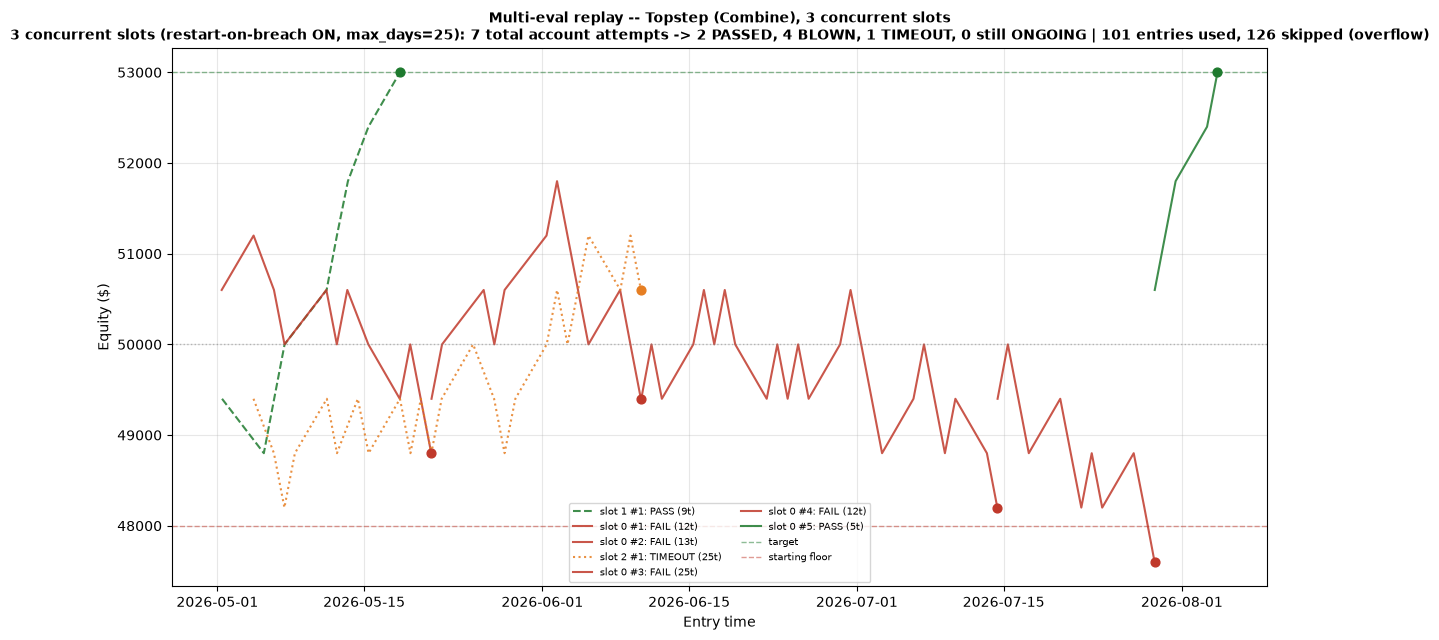

In [21]:
fig = plot_multi_eval(res_n, FIRM)
plt.show()

## 6b) Multi-eval across the top 10 risk-geometry cells
Section 6 above only replays Section 1's single `best` cell. This runs the
SAME `N_ACCOUNTS`-slot, restart-on-breach multi-eval replay (same
`bars_oos`, same `MULTI_EVAL_MAX_DAYS`) across the top 10 cells from
`summary_table_3d()` instead -- the exact same ranked list Section 2 prints
as text -- so the single-account IS pass_pct/days_to_pass that picked each
cell can be compared side by side against what actually happened when that
cell's signals get run through 3 concurrent, restart-on-breach accounts
over real OOS history.

A different stop width needs its own fresh `Entries` ledger (built on
`bars_oos`, `detail=True` for the timestamps `multi_account_replay()`
needs) -- cached per stop width below so cells sharing a stop (common,
since `STOP_GRID` is coarser than the risk%/R:R grids) don't rebuild it
redundantly.

In [22]:
# Same ranked list Section 2 prints -- top 10 cells by IS pass_pct, already
# constrained to MAX_DAYS_TO_PASS (single-account pace).
top10 = summary_table_3d(g, top_n=10, max_days_to_pass=MAX_DAYS_TO_PASS)

entries_oos_by_stop = {}   # cache -- multiple rows often share a stop width
rows_multi = []
results_top10 = []         # (rank, row, MultiEvalResult) -- kept for the chart cell below

for rank, row in enumerate(top10.itertuples(index=False), start=1):
    sp = row.stop_pts
    if sp not in entries_oos_by_stop:
        entries_oos_by_stop[sp] = backtest_entries_verify(strat, bars_oos, stop_points=sp,
                                                           max_hold=MAX_HOLD, detail=True)
    E_i = entries_oos_by_stop[sp]

    res_i = multi_account_replay(E_i, FIRM, risk_pct=row.risk_pct, rr=row.rr,
                                 n_accounts=N_ACCOUNTS, max_days=MULTI_EVAL_MAX_DAYS,
                                 restart_on_fail=True)
    results_top10.append((rank, row, res_i))
    rows_multi.append(dict(
        rank=rank, stop_pts=sp, target_pts=sp * row.rr, rr=row.rr, risk_pct=row.risk_pct,
        is_pass_pct=row.pass_pct, is_days_to_pass=row.days_to_pass,
        attempts=res_i.n_attempts, passed=res_i.n_passed, blown=res_i.n_blown,
        timeout=res_i.n_timeout, multi_pass_rate=res_i.pass_rate * 100,
        entries_used=res_i.entries_used,
    ))

multi_top10_df = pd.DataFrame(rows_multi)
print(f"Multi-eval ({N_ACCOUNTS} slots, restart-on-breach, max_days={MULTI_EVAL_MAX_DAYS}) "
      f"across the top {len(top10)} IS cells, replayed on the full bars_oos "
      f"({len(bars_oos.index.normalize().unique())} days):\n")
print(multi_top10_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\n'multi_pass_rate' = passed / (passed + blown) -- see MultiEvalResult.pass_rate docstring "
      f"(excludes TIMEOUT/ONGOING attempts from the denominator, same convention as Section 6).")

Multi-eval (3 slots, restart-on-breach, max_days=25) across the top 10 IS cells, replayed on the full bars_oos (93 days):

 rank  stop_pts  target_pts    rr  risk_pct  is_pass_pct  is_days_to_pass  attempts  passed  blown  timeout  multi_pass_rate  entries_used
    1    25.000      25.000 1.000     1.200       45.150            8.007         7       2      4        1           33.333           101
    2    25.000      25.000 1.000     1.500       44.250            5.779         5       3      2        0           60.000            46
    3    25.000      75.000 3.000     0.600       43.550            9.735         5       3      2        0           60.000           103
    4    30.000      75.000 2.500     1.200       43.200            5.130         4       3      1        0           75.000            24
    5    30.000      60.000 2.000     1.200       42.250            6.186         7       3      4        0           42.857            69
    6    25.000      75.000 3.000     0.750

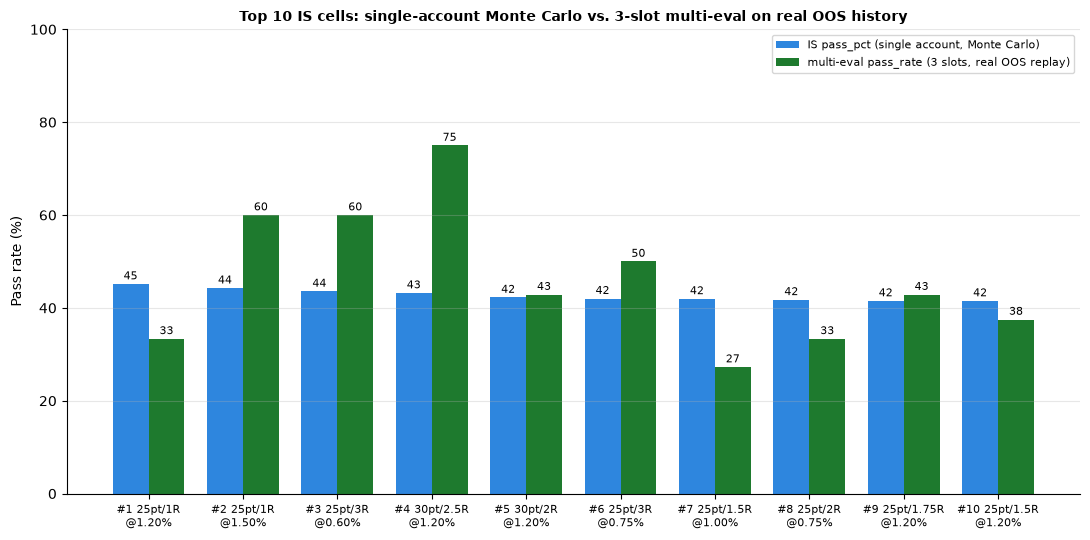

In [23]:
# === Grouped bar chart: IS single-account pass_pct vs. multi-eval pass_rate, per cell ===
fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(multi_top10_df))
w = 0.38
labels = [f"#{r.rank} {r.stop_pts:g}pt/{r.rr:g}R\n@{r.risk_pct:.2f}%" for r in multi_top10_df.itertuples()]

b1 = ax.bar(x - w/2, multi_top10_df["is_pass_pct"], width=w, color="#2e86de",
           label="IS pass_pct (single account, Monte Carlo)")
b2 = ax.bar(x + w/2, multi_top10_df["multi_pass_rate"], width=w, color="#1e7a2e",
           label=f"multi-eval pass_rate ({N_ACCOUNTS} slots, real OOS replay)")

for bar_group in (b1, b2):
    for bar in bar_group:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2, h + 1, f"{h:.0f}", ha="center", fontsize=8)

ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
ax.set_ylabel("Pass rate (%)")
ax.set_ylim(0, 100)
ax.set_title(f"Top {len(multi_top10_df)} IS cells: single-account Monte Carlo vs. "
            f"{N_ACCOUNTS}-slot multi-eval on real OOS history", fontweight="bold", fontsize=10)
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.3, axis="y")
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
fig.tight_layout()
plt.show()

## 6c) FULL-SAMPLE baseline multi-eval
**Not a held-out test -- read alongside Section 6, not instead of it.** Same
single `g["best"]` cell, same `N_ACCOUNTS`/`MULTI_EVAL_MAX_DAYS`, replayed on
`bars` (~508 days) instead of just `bars_oos` (93 days) -- more calendar
time for `N_ACCOUNTS` slots to accumulate attempts, at the cost of
re-including `bars_is`, the very data `g["best"]` was picked on. See 4d's
markdown for the full caveat (identical reasoning, different section).

In [24]:
E_multi_full = backtest_entries_verify(strat, bars, stop_points=best["stop_points"],
                                       max_hold=MAX_HOLD, detail=True)

res_1_full = multi_account_replay(E_multi_full, FIRM, risk_pct=best["risk_pct"], rr=best["rr"],
                                  n_accounts=1, max_days=MULTI_EVAL_MAX_DAYS, restart_on_fail=True)
res_n_full = multi_account_replay(E_multi_full, FIRM, risk_pct=best["risk_pct"], rr=best["rr"],
                                  n_accounts=N_ACCOUNTS, max_days=MULTI_EVAL_MAX_DAYS, restart_on_fail=True)

print(f"FULL-SAMPLE ({len(bars.index.normalize().unique())} days, NOT a held-out test) -- "
      f"{best['stop_points']:g}pt stop / {best['rr']:g}R @ {best['risk_pct']:.2f}% risk, "
      f"{len(E_multi_full.day_ids)} entries after one_position gating\n")
print("1 concurrent slot :", res_1_full.summary())
print(f"{N_ACCOUNTS} concurrent slots:", res_n_full.summary())

print(f"\nOOS-only (Section 6) vs FULL-SAMPLE (this section), {N_ACCOUNTS} slots:")
print(f"  OOS:         {res_n.n_attempts} attempts -> {res_n.n_passed} PASS / {res_n.n_blown} BLOWN "
      f"/ {res_n.n_timeout} TIMEOUT  (pass_rate={res_n.pass_rate:.0%})")
print(f"  Full sample: {res_n_full.n_attempts} attempts -> {res_n_full.n_passed} PASS / "
      f"{res_n_full.n_blown} BLOWN / {res_n_full.n_timeout} TIMEOUT  (pass_rate={res_n_full.pass_rate:.0%})")

FULL-SAMPLE (508 days, NOT a held-out test) -- 25pt stop / 1R @ 1.20% risk, 1085 entries after one_position gating

1 concurrent slot : 1 concurrent slots (restart-on-breach ON, max_days=25): 1 total account attempts -> 1 PASSED, 0 BLOWN, 0 TIMEOUT, 0 still ONGOING | 5 entries used, 1080 skipped (overflow)
3 concurrent slots: 3 concurrent slots (restart-on-breach ON, max_days=25): 5 total account attempts -> 3 PASSED, 2 BLOWN, 0 TIMEOUT, 0 still ONGOING | 53 entries used, 1032 skipped (overflow)

OOS-only (Section 6) vs FULL-SAMPLE (this section), 3 slots:
  OOS:         7 attempts -> 2 PASS / 4 BLOWN / 1 TIMEOUT  (pass_rate=33%)
  Full sample: 5 attempts -> 3 PASS / 2 BLOWN / 0 TIMEOUT  (pass_rate=60%)


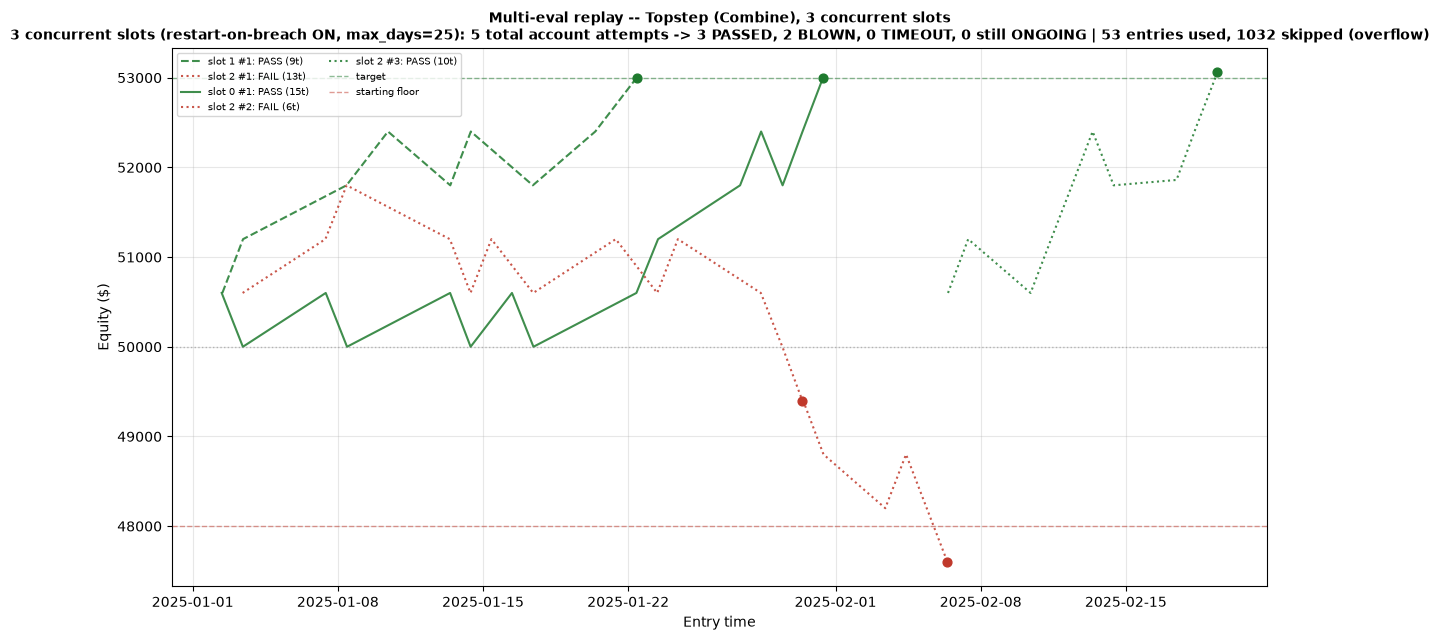

In [25]:
fig = plot_multi_eval(res_n_full, FIRM)
plt.show()

## 6d) FULL-SAMPLE multi-eval across the top 10 risk-geometry cells
**Not a held-out test -- read alongside 6b, not instead of it.** Same top-10
stop/R:R/risk% cells as 6b, replayed on `bars` (~508 days) instead of just
`bars_oos` (93 days). See 4d's markdown for the full caveat (identical
reasoning: these cells were selected on `bars_is`, so re-including it here
biases the numbers optimistic relative to 6b's genuine OOS read).

In [26]:
# Self-contained -- same pattern as 6b, bars_oos -> bars (full sample).
entries_full_by_stop = {}
rows_multi_full = []
results_top10_full = []

for rank, row in enumerate(top10.itertuples(index=False), start=1):
    sp = row.stop_pts
    if sp not in entries_full_by_stop:
        entries_full_by_stop[sp] = backtest_entries_verify(strat, bars, stop_points=sp,
                                                            max_hold=MAX_HOLD, detail=True)
    E_i = entries_full_by_stop[sp]

    res_i = multi_account_replay(E_i, FIRM, risk_pct=row.risk_pct, rr=row.rr,
                                 n_accounts=N_ACCOUNTS, max_days=MULTI_EVAL_MAX_DAYS,
                                 restart_on_fail=True)
    results_top10_full.append((rank, row, res_i))
    rows_multi_full.append(dict(
        rank=rank, stop_pts=sp, target_pts=sp * row.rr, rr=row.rr, risk_pct=row.risk_pct,
        is_pass_pct=row.pass_pct, is_days_to_pass=row.days_to_pass,
        attempts=res_i.n_attempts, passed=res_i.n_passed, blown=res_i.n_blown,
        timeout=res_i.n_timeout, multi_pass_rate=res_i.pass_rate * 100,
        entries_used=res_i.entries_used,
    ))

multi_top10_full_df = pd.DataFrame(rows_multi_full)
print(f"FULL-SAMPLE multi-eval ({N_ACCOUNTS} slots, restart-on-breach, max_days={MULTI_EVAL_MAX_DAYS}) "
      f"across the top {len(top10)} IS cells, replayed on the FULL sample "
      f"({len(bars.index.normalize().unique())} days -- NOT a held-out test):\n")
print(multi_top10_full_df.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

compare6 = multi_top10_df[["rank", "attempts", "passed", "blown", "multi_pass_rate"]].merge(
    multi_top10_full_df[["rank", "attempts", "passed", "blown", "multi_pass_rate"]],
    on="rank", suffixes=("_oos", "_full"))
print("\nOOS (6b) vs FULL-SAMPLE (6d), side by side:")
print(compare6.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

FULL-SAMPLE multi-eval (3 slots, restart-on-breach, max_days=25) across the top 10 IS cells, replayed on the FULL sample (508 days -- NOT a held-out test):

 rank  stop_pts  target_pts    rr  risk_pct  is_pass_pct  is_days_to_pass  attempts  passed  blown  timeout  multi_pass_rate  entries_used
    1    25.000      25.000 1.000     1.200       45.150            8.007         5       3      2        0           60.000            53
    2    25.000      25.000 1.000     1.500       44.250            5.779         4       3      1        0           75.000            45
    3    25.000      75.000 3.000     0.600       43.550            9.735         4       1      1        2           50.000            90
    4    30.000      75.000 2.500     1.200       43.200            5.130         5       3      2        0           60.000            49
    5    30.000      60.000 2.000     1.200       42.250            6.186         4       2      1        1           66.667            43
    6    